# Online Retail — Full Data Analysis Project
### Pandas • Matplotlib • Seaborn • Plotly


**Dataset source:** [Online Retail Dataset — Kaggle](https://www.kaggle.com/datasets/vijayuv/onlineretail)

**Dataset facts:** The commonly distributed version contains approximately 541,909 transaction rows and fields such as invoice number, product code, description, quantity, invoice date, unit price, customer ID, and country. Your downloaded file may differ slightly, so always inspect it rather than assuming exact counts.



---

## 0. Environment setup and dataset loading

You can download the dataset through KaggleHub. If Kaggle authentication or package access is unavailable, download the dataset manually from the Kaggle page and update the file path below.

**Expected source file:** The original Online Retail dataset is commonly distributed as an Excel file (`.xlsx`). Your Kaggle copy may provide a CSV instead.

In [42]:
%pip install kagglehub

Note: you may need to restart the kernel to use updated packages.


In [43]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Dataset path
file_path = r"C:\Users\altawkeel\Downloads\archive(4)\OnlineRetail.csv"

# Check if file exists
if os.path.exists(file_path):
    print("Dataset file found successfully.")
else:
    print("Dataset file was not found.")

# Load dataset
df = pd.read_csv(file_path, encoding="ISO-8859-1")

# Initial inspection
print("\nDataset loaded successfully.")
print("File:", file_path)
print("Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all").T)

Dataset file found successfully.

Dataset loaded successfully.
File: C:\Users\altawkeel\Downloads\archive(4)\OnlineRetail.csv
Shape: (541909, 8)

First 5 Rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom



Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data Types:
InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,218.081158,-80995.0,1.0,3.0,10.0,80995.0
InvoiceDate,541909,23260,10/31/2011 14:41,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,1713.600303,12346.0,13953.0,15152.0,16791.0,18287.0
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


---

# Part 1 — Data Understanding & Initial Inspection (Questions 1–5)

### Q1. First look
Display the first 10 rows and last 10 rows. Based on the columns, explain what one row represents.

### Q2. Dataset dimensions
Find the number of rows and columns. Calculate the memory usage of the DataFrame and identify whether the dataset is large enough to require careful memory handling.

### Q3. Schema inspection
Display column names, data types, and non-null counts. Which columns have incorrect or unexpected data types?

### Q4. Statistical overview
Generate descriptive statistics for numeric and categorical columns separately. Write down at least three observations.

### Q5. Cardinality check
For each column, calculate the number of unique values. Identify columns that behave like identifiers and columns that represent categories.

In [44]:
# Q1–Q5: Write your Pandas inspection code here.
# Q1. First Look
print("=" * 60)
print("Q1. FIRST 10 ROWS")
print("=" * 60)
display(df.head(10))

print("\n" + "=" * 60)
print("Q1. LAST 10 ROWS")
print("=" * 60)
display(df.tail(10))

print("\nEach row represents a single transaction line in the Online Retail dataset,")
print("containing information about an invoice, product, quantity, date, price,")
print("customer, and country.")


# Q2. Dataset Dimensions
print("\n" + "=" * 60)
print("Q2. DATASET DIMENSIONS")
print("=" * 60)

rows, columns = df.shape
memory_bytes = df.memory_usage(deep=True).sum()
memory_mb = memory_bytes / (1024 ** 2)

print(f"Number of Rows: {rows}")
print(f"Number of Columns: {columns}")
print(f"Memory Usage: {memory_mb:.2f} MB")

if memory_mb < 100:
    print("The dataset is relatively small and can normally be handled comfortably in memory.")
elif memory_mb < 500:
    print("The dataset is moderately large, so memory usage should be monitored.")
else:
    print("The dataset is large and requires careful memory handling.")


# Q3. Schema Inspection
print("\n" + "=" * 60)
print("Q3. SCHEMA INSPECTION")
print("=" * 60)

schema = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str),
    "Non-Null Count": df.notna().sum().values
})

display(schema)

print("\nDetailed Dataset Information:")
df.info()

print("\nColumns with Object Data Type:")
print(df.select_dtypes(include="object").columns.tolist())

print("\nExpected Data Type Review:")
if "InvoiceDate" in df.columns:
    print(f"InvoiceDate current type: {df['InvoiceDate'].dtype}")
    if not pd.api.types.is_datetime64_any_dtype(df["InvoiceDate"]):
        print("InvoiceDate should be converted to datetime during data cleaning.")


# Q4. Statistical Overview
print("\n" + "=" * 60)
print("Q4. STATISTICAL OVERVIEW")
print("=" * 60)

numeric_columns = df.select_dtypes(include=np.number).columns
categorical_columns = df.select_dtypes(include="object").columns

print("Numerical Columns:")
print(numeric_columns.tolist())

print("\nCategorical Columns:")
print(categorical_columns.tolist())

print("\nDescriptive Statistics for Numerical Columns:")
display(df[numeric_columns].describe().T)

print("\nDescriptive Statistics for Categorical Columns:")
display(df[categorical_columns].describe().T)

print("\nObservations:")
print("1. Quantity and UnitPrice are the main numerical variables used to describe purchases.")
print("2. Quantity may contain negative values, which can indicate returned or cancelled items.")
print("3. Country is a categorical variable representing the customer's country.")


# Q5. Cardinality Check
print("\n" + "=" * 60)
print("Q5. CARDINALITY CHECK")
print("=" * 60)

cardinality = pd.DataFrame({
    "Column": df.columns,
    "Unique Values": [df[col].nunique() for col in df.columns],
    "Data Type": df.dtypes.astype(str).values
})

display(cardinality.sort_values("Unique Values", ascending=False))

print("\nPotential Identifier Columns:")
for col in df.columns:
    unique_ratio = df[col].nunique() / len(df)
    if unique_ratio > 0.5:
        print(f"- {col}: {df[col].nunique()} unique values")

print("\nPotential Categorical Columns:")
for col in df.columns:
    unique_values = df[col].nunique()
    if unique_values < 100:
        print(f"- {col}: {unique_values} unique values")

print("\nPart 1 completed successfully.")

Q1. FIRST 10 ROWS


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,12/1/2010 8:26,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/1/2010 8:26,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,12/1/2010 8:34,1.69,13047.0,United Kingdom



Q1. LAST 10 ROWS


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541899,581587,22726,ALARM CLOCK BAKELIKE GREEN,4,12/9/2011 12:50,3.75,12680.0,France
541900,581587,22730,ALARM CLOCK BAKELIKE IVORY,4,12/9/2011 12:50,3.75,12680.0,France
541901,581587,22367,CHILDRENS APRON SPACEBOY DESIGN,8,12/9/2011 12:50,1.95,12680.0,France
541902,581587,22629,SPACEBOY LUNCH BOX,12,12/9/2011 12:50,1.95,12680.0,France
541903,581587,23256,CHILDRENS CUTLERY SPACEBOY,4,12/9/2011 12:50,4.15,12680.0,France
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/2011 12:50,4.95,12680.0,France



Each row represents a single transaction line in the Online Retail dataset,
containing information about an invoice, product, quantity, date, price,
customer, and country.

Q2. DATASET DIMENSIONS
Number of Rows: 541909
Number of Columns: 8
Memory Usage: 173.12 MB
The dataset is moderately large, so memory usage should be monitored.

Q3. SCHEMA INSPECTION


,Column,Data Type,Non-Null Count
InvoiceNo,InvoiceNo,object,541909
StockCode,StockCode,object,541909
Description,Description,object,540455
Quantity,Quantity,int64,541909
InvoiceDate,InvoiceDate,object,541909
UnitPrice,UnitPrice,float64,541909
CustomerID,CustomerID,float64,406829
Country,Country,object,541909


... (3 outputs left out)

,count,unique,top,freq
InvoiceNo,541909,25900,573585,1114
StockCode,541909,4070,85123A,2313
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369
InvoiceDate,541909,23260,10/31/2011 14:41,1114
Country,541909,38,United Kingdom,495478



Observations:
1. Quantity and UnitPrice are the main numerical variables used to describe purchases.
2. Quantity may contain negative values, which can indicate returned or cancelled items.
3. Country is a categorical variable representing the customer's country.

Q5. CARDINALITY CHECK


,Column,Unique Values,Data Type
0,InvoiceNo,25900,object
4,InvoiceDate,23260,object
6,CustomerID,4372,float64
2,Description,4223,object
1,StockCode,4070,object
5,UnitPrice,1630,float64
3,Quantity,722,int64
7,Country,38,object



Potential Identifier Columns:

Potential Categorical Columns:
- Country: 38 unique values

Part 1 completed successfully.


---

# Part 2 — Data Quality Investigation (Questions 6–13)

### Q6. Missing values report
Calculate the missing-value count and missing-value percentage for every column. Sort the report by missing percentage.

### Q7. Missingness visualization
Create a visualization showing the distribution or pattern of missing values. Which columns are most affected?

### Q8. Duplicate investigation
Count fully duplicated rows. Display a sample of duplicates and investigate whether they are exact repeated records.

### Q9. Invoice and cancellation analysis
Inspect `InvoiceNo`. Identify cancellation invoices (commonly invoices whose number starts with `C`). Count them and calculate their share of all rows.

### Q10. Quantity validation
Investigate zero and negative values in `Quantity`. Are negative quantities necessarily errors? Explain how they may relate to returns or cancellations.

### Q11. Unit price validation
Investigate zero and negative values in `UnitPrice`. Count affected records and inspect examples before deciding how to handle them.

### Q12. Product description quality
Inspect missing and repeated values in `Description`. Identify whether product codes appear with multiple descriptions.

### Q13. Customer and country quality
Investigate missing `CustomerID` values and inspect the distribution of `Country`. Decide which analyses can be performed without customer IDs.

Q6. MISSING VALUES REPORT


,Missing Count,Missing Percentage
CustomerID,135080,24.93
Description,1454,0.27
InvoiceNo,0,0.00
StockCode,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00



Q7. MISSINGNESS VISUALIZATION


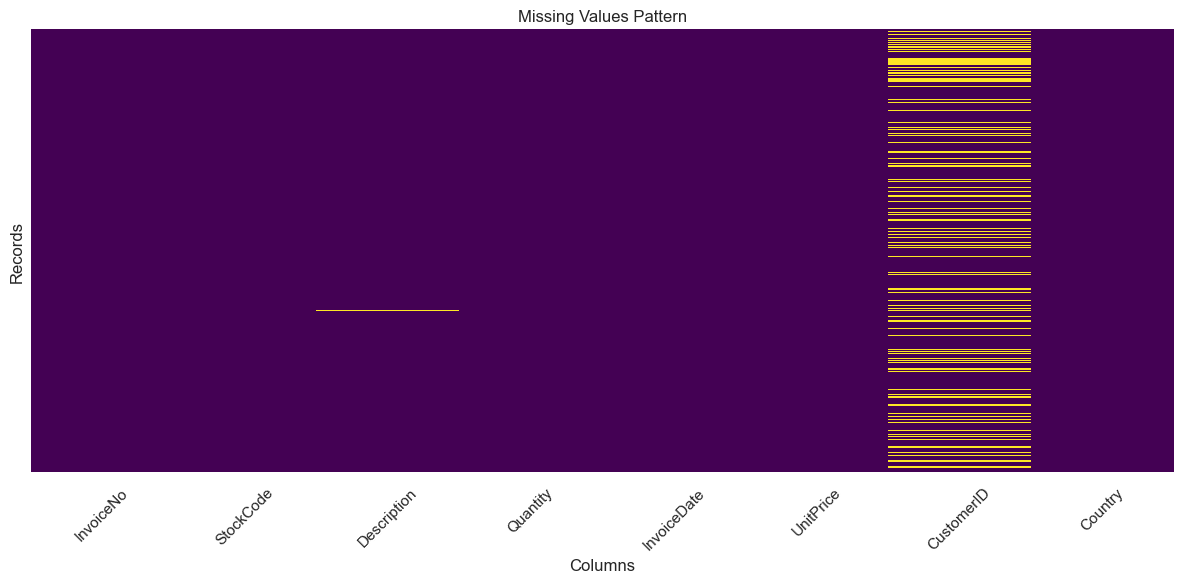

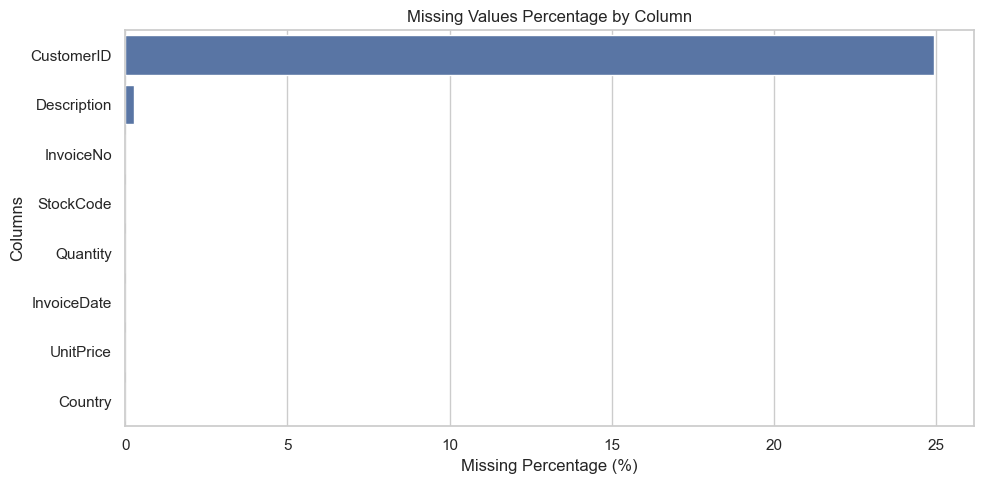

Most affected columns:
             Missing Count  Missing Percentage
CustomerID          135080           24.926694
Description           1454            0.268311

Q8. DUPLICATE INVESTIGATION
Total Duplicate Rows: 5268
Duplicate Percentage: 0.97 %

Sample of Duplicate Records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,12/1/2010 11:49,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,12/1/2010 11:49,2.95,17920.0,United Kingdom



Exact Duplicate Check:
All identified duplicates have identical values across all columns: True

Q9. INVOICE AND CANCELLATION ANALYSIS
Total Rows: 541909
Cancellation Records: 9288
Cancellation Share: 1.71%

Cancellation Invoice Examples:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/2010 9:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/2010 9:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,12/1/2010 10:24,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,12/1/2010 10:24,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,12/1/2010 12:38,4.25,17897.0,United Kingdom



Normal Invoice Examples:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,12/1/2010 8:26,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/1/2010 8:26,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,12/1/2010 8:34,1.69,13047.0,United Kingdom


... (15 outputs left out)

,Transaction Records
Country,
United Kingdom,495478
Germany,9495
France,8557
EIRE,8196
Spain,2533
Netherlands,2371
Belgium,2069
Switzerland,2002
Portugal,1519



Top 10 Countries:


,Transaction Records
Country,
United Kingdom,495478
Germany,9495
France,8557
EIRE,8196
Spain,2533
Netherlands,2371
Belgium,2069
Switzerland,2002
Portugal,1519



Missing Country Values: 0


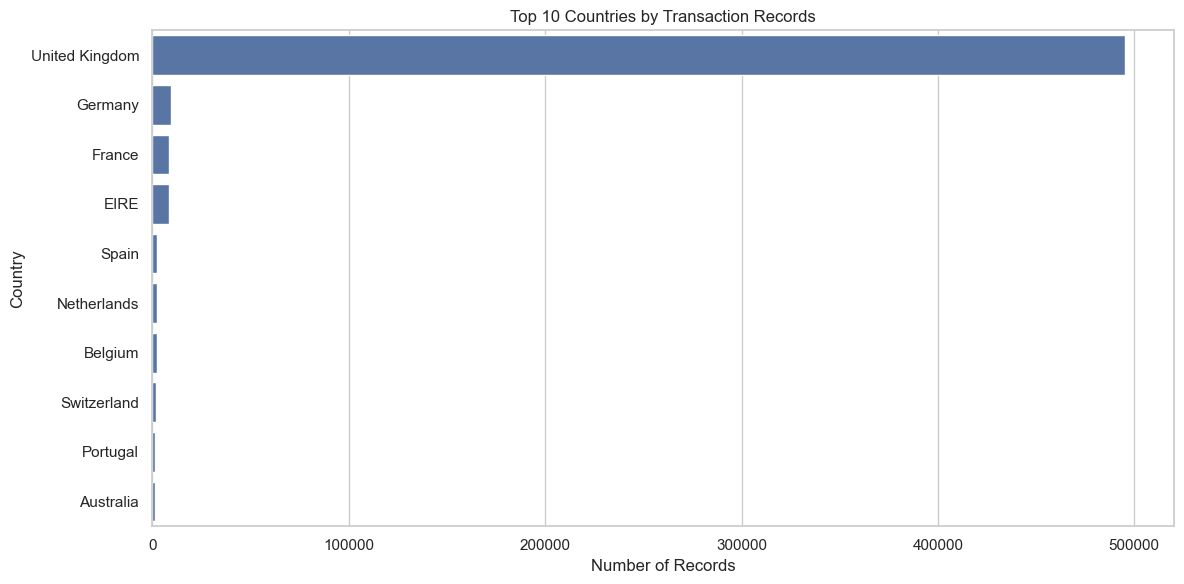


Analysis Decision:
Sales analysis can be performed using invoice, product, quantity,
price, date, and country information without CustomerID.
Customer-specific analysis requires valid CustomerID values.
Missing CustomerID records should be handled according to the
requirements of each analysis.

PART 2 COMPLETED SUCCESSFULLY
Total Rows: 541909
Total Columns: 8
Missing Values: 136534
Duplicate Rows: 5268
Cancellation Records: 9288
Zero Quantity: 0
Negative Quantity: 10624
Zero UnitPrice: 2515
Negative UnitPrice: 2
Missing CustomerID: 135080
Missing Description: 1454


In [45]:
# Q6–Q13: Write your data quality investigation code here.
# Q6. Missing Values Report
print("=" * 70)
print("Q6. MISSING VALUES REPORT")
print("=" * 70)

missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_report = missing_report.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_report.round(2))


# Q7. Missingness Visualization
print("\n" + "=" * 70)
print("Q7. MISSINGNESS VISUALIZATION")
print("=" * 70)

plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values Pattern")
plt.xlabel("Columns")
plt.ylabel("Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))

missing_percent = df.isnull().mean().sort_values(ascending=False) * 100

sns.barplot(
    x=missing_percent.values,
    y=missing_percent.index
)

plt.title("Missing Values Percentage by Column")
plt.xlabel("Missing Percentage (%)")
plt.ylabel("Columns")
plt.tight_layout()
plt.show()

print("Most affected columns:")
print(missing_report[missing_report["Missing Count"] > 0])


# Q8. Duplicate Investigation
print("\n" + "=" * 70)
print("Q8. DUPLICATE INVESTIGATION")
print("=" * 70)

duplicate_count = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)
print("Duplicate Percentage:", round(duplicate_count / len(df) * 100, 2), "%")

duplicates = df[df.duplicated(keep=False)]

print("\nSample of Duplicate Records:")
display(duplicates.head(10))

print("\nExact Duplicate Check:")
print("All identified duplicates have identical values across all columns:",
      df.duplicated().any())


# Q9. Invoice and Cancellation Analysis
print("\n" + "=" * 70)
print("Q9. INVOICE AND CANCELLATION ANALYSIS")
print("=" * 70)

df["InvoiceNo"] = df["InvoiceNo"].astype(str)

cancellation_mask = df["InvoiceNo"].str.startswith("C", na=False)

cancellation_count = cancellation_mask.sum()
total_rows = len(df)

cancellation_percentage = (cancellation_count / total_rows) * 100

print("Total Rows:", total_rows)
print("Cancellation Records:", cancellation_count)
print(f"Cancellation Share: {cancellation_percentage:.2f}%")

print("\nCancellation Invoice Examples:")
display(df[cancellation_mask].head(10))

print("\nNormal Invoice Examples:")
display(df[~cancellation_mask].head(10))


# Q10. Quantity Validation
print("\n" + "=" * 70)
print("Q10. QUANTITY VALIDATION")
print("=" * 70)

zero_quantity = (df["Quantity"] == 0).sum()
negative_quantity = (df["Quantity"] < 0).sum()
positive_quantity = (df["Quantity"] > 0).sum()

print("Zero Quantity Records:", zero_quantity)
print("Negative Quantity Records:", negative_quantity)
print("Positive Quantity Records:", positive_quantity)

print("\nNegative Quantity Examples:")
display(df[df["Quantity"] < 0].head(10))

print("\nNegative Quantities in Cancellation Invoices:")
print(df.loc[cancellation_mask & (df["Quantity"] < 0)].shape[0])

print("\nNegative Quantities in Normal Invoices:")
print(df.loc[~cancellation_mask & (df["Quantity"] < 0)].shape[0])

print("\nObservation:")
print("Negative quantities may represent returned products or cancelled transactions.")
print("They should not automatically be considered errors.")


# Q11. Unit Price Validation
print("\n" + "=" * 70)
print("Q11. UNIT PRICE VALIDATION")
print("=" * 70)

zero_price = (df["UnitPrice"] == 0).sum()
negative_price = (df["UnitPrice"] < 0).sum()
positive_price = (df["UnitPrice"] > 0).sum()

print("Zero UnitPrice Records:", zero_price)
print("Negative UnitPrice Records:", negative_price)
print("Positive UnitPrice Records:", positive_price)

print("\nZero Price Examples:")
display(df[df["UnitPrice"] == 0].head(10))

print("\nNegative Price Examples:")
display(df[df["UnitPrice"] < 0].head(10))

print("\nUnit Price Statistics:")
display(df["UnitPrice"].describe())

print("\nObservation:")
print("Zero prices may represent promotional or free items.")
print("Negative prices should be investigated before removing any records.")


# Q12. Product Description Quality
print("\n" + "=" * 70)
print("Q12. PRODUCT DESCRIPTION QUALITY")
print("=" * 70)

missing_descriptions = df["Description"].isnull().sum()

print("Missing Descriptions:", missing_descriptions)
print("Unique Descriptions:", df["Description"].nunique())

print("\nMost Repeated Product Descriptions:")
display(
    df["Description"].value_counts().head(10).to_frame("Frequency")
)

print("\nProduct Codes with Multiple Descriptions:")

product_descriptions = (
    df.dropna(subset=["StockCode", "Description"])
      .groupby("StockCode")["Description"]
      .nunique()
)

multiple_descriptions = product_descriptions[
    product_descriptions > 1
].sort_values(ascending=False)

print("Number of Product Codes with Multiple Descriptions:",
      len(multiple_descriptions))

display(multiple_descriptions.head(10).to_frame("Number of Descriptions"))

print("\nExamples of Product Codes with Multiple Descriptions:")

if len(multiple_descriptions) > 0:
    sample_codes = multiple_descriptions.head(5).index

    display(
        df[df["StockCode"].isin(sample_codes)]
        [["StockCode", "Description"]]
        .drop_duplicates()
        .sort_values("StockCode")
    )


# Q13. Customer and Country Quality
print("\n" + "=" * 70)
print("Q13. CUSTOMER AND COUNTRY QUALITY")
print("=" * 70)

missing_customers = df["CustomerID"].isnull().sum()
missing_customer_percentage = (missing_customers / len(df)) * 100

print("Missing CustomerID Records:", missing_customers)
print(f"Missing CustomerID Percentage: {missing_customer_percentage:.2f}%")

print("\nUnique Customers:")
print(df["CustomerID"].nunique())

print("\nCountry Distribution:")
country_distribution = df["Country"].value_counts()

display(country_distribution.to_frame("Transaction Records"))

print("\nTop 10 Countries:")
display(country_distribution.head(10).to_frame("Transaction Records"))

print("\nMissing Country Values:", df["Country"].isnull().sum())

plt.figure(figsize=(12, 6))

sns.barplot(
    x=country_distribution.head(10).values,
    y=country_distribution.head(10).index
)

plt.title("Top 10 Countries by Transaction Records")
plt.xlabel("Number of Records")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

print("\nAnalysis Decision:")
print("Sales analysis can be performed using invoice, product, quantity,")
print("price, date, and country information without CustomerID.")
print("Customer-specific analysis requires valid CustomerID values.")
print("Missing CustomerID records should be handled according to the")
print("requirements of each analysis.")


# Final Summary
print("\n" + "=" * 70)
print("PART 2 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Total Rows:", len(df))
print("Total Columns:", len(df.columns))
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", duplicate_count)
print("Cancellation Records:", cancellation_count)
print("Zero Quantity:", zero_quantity)
print("Negative Quantity:", negative_quantity)
print("Zero UnitPrice:", zero_price)
print("Negative UnitPrice:", negative_price)
print("Missing CustomerID:", missing_customers)
print("Missing Description:", missing_descriptions)

---

# Part 3 — Data Cleaning & Feature Engineering (Questions 14–18)

### Q14. Define a cleaning strategy
Before changing the data, write a short plan. Explain how you will handle:
- Missing customer IDs and descriptions.
- Exact duplicate rows.
- Cancellation invoices.
- Negative quantities and zero/negative prices.
- Incorrect data types.

Do not delete returns or cancellations without explaining the analytical purpose.

### Q15. Apply cleaning steps
Create a separate DataFrame named `clean_df`. Apply your chosen cleaning strategy and document how many rows were removed or changed at each step.

### Q16. Convert data types
Ensure `InvoiceDate` is datetime and `CustomerID` is handled consistently. Convert other fields to appropriate types where justified.

### Q17. Create transaction revenue
Create a `Revenue` column using `Quantity * UnitPrice`. Explain how this calculation behaves for negative quantities and cancellation records.

### Q18. Create date features
Create `Year`, `Month`, `MonthName`, `DayName`, and `Hour` from `InvoiceDate`. Keep a chronological month order for later charts.

In [46]:
# Q14–Q18: Write your cleaning and feature-engineering code here.
# Q14. Define a Cleaning Strategy
print("=" * 70)
print("Q14. CLEANING STRATEGY")
print("=" * 70)

cleaning_strategy = """
1. Missing CustomerID:
   Keep records with missing CustomerID for general sales analysis.
   Exclude them only from customer-specific analysis.

2. Missing Description:
   Keep the records because StockCode and transaction information
   may still be useful for sales analysis.

3. Exact Duplicate Rows:
   Remove fully duplicated records to avoid double counting.

4. Cancellation Invoices:
   Keep cancellation records to preserve transaction history.
   They can be excluded from normal sales analysis when necessary.

5. Negative Quantities:
   Keep negative quantities because they may represent product returns.

6. Zero or Negative UnitPrice:
   Keep these records during investigation.
   Negative prices require further inspection, while zero prices
   may represent free items or adjustments.

7. Incorrect Data Types:
   Convert InvoiceDate to datetime.
   Convert CustomerID to nullable integer.
   Convert other columns where appropriate.
"""

print(cleaning_strategy)


# Q15. Apply Cleaning Steps
print("\n" + "=" * 70)
print("Q15. APPLY CLEANING STEPS")
print("=" * 70)

clean_df = df.copy()

original_rows = len(clean_df)

print("Original Number of Rows:", original_rows)

# Remove exact duplicates
duplicates_before = clean_df.duplicated().sum()

clean_df = clean_df.drop_duplicates().copy()

duplicates_removed = duplicates_before

print("Duplicate Rows Removed:", duplicates_removed)
print("Rows After Duplicate Removal:", len(clean_df))

# Missing values investigation
missing_customer_before = clean_df["CustomerID"].isnull().sum()
missing_description_before = clean_df["Description"].isnull().sum()

print("\nMissing CustomerID Records Kept:", missing_customer_before)
print("Missing Description Records Kept:", missing_description_before)

# Cancellation records
cancellation_mask = clean_df["InvoiceNo"].astype(str).str.startswith("C", na=False)

cancellation_records = cancellation_mask.sum()

print("\nCancellation Records Kept:", cancellation_records)

# Negative and zero values
negative_quantity_count = (clean_df["Quantity"] < 0).sum()
zero_quantity_count = (clean_df["Quantity"] == 0).sum()

zero_price_count = (clean_df["UnitPrice"] == 0).sum()
negative_price_count = (clean_df["UnitPrice"] < 0).sum()

print("\nNegative Quantity Records Kept:", negative_quantity_count)
print("Zero Quantity Records Kept:", zero_quantity_count)
print("Zero UnitPrice Records Kept:", zero_price_count)
print("Negative UnitPrice Records Kept:", negative_price_count)

# Cleaning summary
removed_rows = original_rows - len(clean_df)
changed_rows = removed_rows

print("\nCleaning Summary:")
print("Original Rows:", original_rows)
print("Final Rows:", len(clean_df))
print("Removed Rows:", removed_rows)
print("Changed Rows:", changed_rows)


# Q16. Convert Data Types
print("\n" + "=" * 70)
print("Q16. DATA TYPE CONVERSION")
print("=" * 70)

# Convert InvoiceDate to datetime
clean_df["InvoiceDate"] = pd.to_datetime(
    clean_df["InvoiceDate"],
    errors="coerce"
)

# Convert CustomerID to nullable integer
clean_df["CustomerID"] = pd.to_numeric(
    clean_df["CustomerID"],
    errors="coerce"
).astype("Int64")

# Convert numerical columns
clean_df["Quantity"] = pd.to_numeric(
    clean_df["Quantity"],
    errors="coerce"
)

clean_df["UnitPrice"] = pd.to_numeric(
    clean_df["UnitPrice"],
    errors="coerce"
)

print("Data Types After Conversion:")
print(clean_df.dtypes)

print("\nDataset Information:")
clean_df.info()


# Q17. Create Transaction Revenue
print("\n" + "=" * 70)
print("Q17. CREATE TRANSACTION REVENUE")
print("=" * 70)

clean_df["Revenue"] = (
    clean_df["Quantity"] * clean_df["UnitPrice"]
)

print("Revenue Column Created Successfully.")

display(
    clean_df[
        ["InvoiceNo", "StockCode", "Quantity", "UnitPrice", "Revenue"]
    ].head(10)
)

print("\nRevenue Statistics:")
display(clean_df["Revenue"].describe())

print("\nRevenue for Negative Quantities:")
display(
    clean_df.loc[
        clean_df["Quantity"] < 0,
        ["InvoiceNo", "Quantity", "UnitPrice", "Revenue"]
    ].head(10)
)

print("\nRevenue for Cancellation Invoices:")
display(
    clean_df.loc[
        clean_df["InvoiceNo"].astype(str).str.startswith("C"),
        ["InvoiceNo", "Quantity", "UnitPrice", "Revenue"]
    ].head(10)
)

print("""
Explanation:
Revenue is calculated by multiplying Quantity by UnitPrice.

Positive quantities usually generate positive revenue.
Negative quantities generate negative revenue, which may represent returns.
Cancellation invoices may also produce negative revenue values.

Keeping these records allows us to analyze both sales and returns.
""")


# Q18. Create Date Features
print("\n" + "=" * 70)
print("Q18. CREATE DATE FEATURES")
print("=" * 70)

# Remove rows with invalid dates because date features cannot be extracted
invalid_dates = clean_df["InvoiceDate"].isnull().sum()

print("Invalid InvoiceDate Records:", invalid_dates)

clean_df = clean_df.dropna(subset=["InvoiceDate"]).copy()

# Extract date features
clean_df["Year"] = clean_df["InvoiceDate"].dt.year

clean_df["Month"] = clean_df["InvoiceDate"].dt.month

clean_df["MonthName"] = clean_df["InvoiceDate"].dt.month_name()

clean_df["DayName"] = clean_df["InvoiceDate"].dt.day_name()

clean_df["Hour"] = clean_df["InvoiceDate"].dt.hour

# Keep chronological month order
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

clean_df["MonthName"] = pd.Categorical(
    clean_df["MonthName"],
    categories=month_order,
    ordered=True
)

print("Date Features Created Successfully.")

display(
    clean_df[
        [
            "InvoiceDate",
            "Year",
            "Month",
            "MonthName",
            "DayName",
            "Hour"
        ]
    ].head(10)
)


# Final Dataset Summary
print("\n" + "=" * 70)
print("PART 3 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Original Dataset Shape:", df.shape)
print("Clean Dataset Shape:", clean_df.shape)

print("Total Rows Removed:", original_rows - len(clean_df))
print("Remaining Missing Values:", clean_df.isnull().sum().sum())

print("\nFinal Columns:")
print(clean_df.columns.tolist())

print("\nFinal Dataset Preview:")
display(clean_df.head(10))

Q14. CLEANING STRATEGY

1. Missing CustomerID:
   Keep records with missing CustomerID for general sales analysis.
   Exclude them only from customer-specific analysis.

2. Missing Description:
   Keep the records because StockCode and transaction information
   may still be useful for sales analysis.

3. Exact Duplicate Rows:
   Remove fully duplicated records to avoid double counting.

4. Cancellation Invoices:
   Keep cancellation records to preserve transaction history.
   They can be excluded from normal sales analysis when necessary.

5. Negative Quantities:
   Keep negative quantities because they may represent product returns.

6. Zero or Negative UnitPrice:
   Keep these records during investigation.
   Negative prices require further inspection, while zero prices
   may represent free items or adjustments.

7. Incorrect Data Types:
   Convert InvoiceDate to datetime.
   Convert CustomerID to nullable integer.
   Convert other columns where appropriate.


Q15. APPLY CLEANING S

,InvoiceNo,StockCode,Quantity,UnitPrice,Revenue
0,536365,85123A,6,2.55,15.30
1,536365,71053,6,3.39,20.34
2,536365,84406B,8,2.75,22.00
3,536365,84029G,6,3.39,20.34
4,536365,84029E,6,3.39,20.34
5,536365,22752,2,7.65,15.30
6,536365,21730,6,4.25,25.50
7,536366,22633,6,1.85,11.10
8,536366,22632,6,1.85,11.10
9,536367,84879,32,1.69,54.08



Revenue Statistics:


count    536641.000000
mean         18.123861
std         380.656263
min     -168469.600000
25%           3.750000
50%           9.870000
75%          17.400000
max      168469.600000
Name: Revenue, dtype: float64


Revenue for Negative Quantities:


,InvoiceNo,Quantity,UnitPrice,Revenue
141,C536379,-1,27.50,-27.50
154,C536383,-1,4.65,-4.65
235,C536391,-12,1.65,-19.80
236,C536391,-24,0.29,-6.96
237,C536391,-24,0.29,-6.96
238,C536391,-24,0.29,-6.96
239,C536391,-12,3.45,-41.40
240,C536391,-12,1.65,-19.80
241,C536391,-24,1.65,-39.60
939,C536506,-6,4.25,-25.50


... (2 outputs left out)


Explanation:
Revenue is calculated by multiplying Quantity by UnitPrice.

Positive quantities usually generate positive revenue.
Negative quantities generate negative revenue, which may represent returns.
Cancellation invoices may also produce negative revenue values.

Keeping these records allows us to analyze both sales and returns.


Q18. CREATE DATE FEATURES
Invalid InvoiceDate Records: 0
Date Features Created Successfully.


,InvoiceDate,Year,Month,MonthName,DayName,Hour
0,2010-12-01 08:26:00,2010,12,December,Wednesday,8
1,2010-12-01 08:26:00,2010,12,December,Wednesday,8
2,2010-12-01 08:26:00,2010,12,December,Wednesday,8
3,2010-12-01 08:26:00,2010,12,December,Wednesday,8
4,2010-12-01 08:26:00,2010,12,December,Wednesday,8
5,2010-12-01 08:26:00,2010,12,December,Wednesday,8
6,2010-12-01 08:26:00,2010,12,December,Wednesday,8
7,2010-12-01 08:28:00,2010,12,December,Wednesday,8
8,2010-12-01 08:28:00,2010,12,December,Wednesday,8
9,2010-12-01 08:34:00,2010,12,December,Wednesday,8



PART 3 COMPLETED SUCCESSFULLY
Original Dataset Shape: (541909, 8)
Clean Dataset Shape: (536641, 14)
Total Rows Removed: 5268
Remaining Missing Values: 136491

Final Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue', 'Year', 'Month', 'MonthName', 'DayName', 'Hour']

Final Dataset Preview:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Year,Month,MonthName,DayName,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010,12,December,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,December,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010,12,December,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,December,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,December,Wednesday,8
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850,United Kingdom,15.30,2010,12,December,Wednesday,8
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850,United Kingdom,25.50,2010,12,December,Wednesday,8
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850,United Kingdom,11.10,2010,12,December,Wednesday,8
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850,United Kingdom,11.10,2010,12,December,Wednesday,8
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047,United Kingdom,54.08,2010,12,December,Wednesday,8


---

# Part 4 — Pandas Business Analysis (Questions 19–24)

### Q19. Top products by quantity
Find the 10 products with the highest total quantity sold. Exclude or separately report returns so that sales and returns are not mixed.

### Q20. Top products by revenue
Find the 10 products with the highest total revenue. Compare the ranking with Q19. Are the same products at the top?

### Q21. Country performance
Calculate total revenue, number of invoices, and average invoice value for each country. Rank countries by revenue and compare the United Kingdom with other countries.

### Q22. Monthly revenue trend
Aggregate revenue by month and year. Which month has the highest revenue? Which month has the lowest? Use a chronological index.

### Q23. Customer analysis
Calculate total spend, number of invoices, and average spend per customer. Identify the top 10 customers by total spend. State how you handled missing CustomerID values.

### Q24. Invoice-level analysis
Group records by `InvoiceNo` to calculate invoice value, number of distinct products, and total quantity. Identify the largest invoices and investigate whether cancellations affect the ranking.

In [47]:
# Q19–Q24: Write your Pandas analysis code here.
# Q19. Top Products by Quantity
print("=" * 70)
print("Q19. TOP PRODUCTS BY QUANTITY")
print("=" * 70)

sales_df = clean_df[
    (clean_df["Quantity"] > 0) &
    (clean_df["UnitPrice"] > 0) &
    (~clean_df["InvoiceNo"].astype(str).str.startswith("C"))
].copy()

returns_df = clean_df[
    (clean_df["Quantity"] < 0) |
    (clean_df["InvoiceNo"].astype(str).str.startswith("C"))
].copy()

top_quantity = (
    sales_df.groupby(["StockCode", "Description"], dropna=False)
    ["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="Total Quantity Sold")
)

print("Top 10 Products by Quantity Sold:")
display(top_quantity)

print("\nTop Returned Products:")
top_returns = (
    returns_df[returns_df["Quantity"] < 0]
    .groupby(["StockCode", "Description"], dropna=False)["Quantity"]
    .sum()
    .sort_values()
    .head(10)
    .reset_index(name="Returned Quantity")
)

display(top_returns)


# Q20. Top Products by Revenue
print("\n" + "=" * 70)
print("Q20. TOP PRODUCTS BY REVENUE")
print("=" * 70)

top_revenue = (
    sales_df.groupby(["StockCode", "Description"], dropna=False)
    ["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="Total Revenue")
)

print("Top 10 Products by Revenue:")
display(top_revenue)

print("\nComparison Between Quantity and Revenue Rankings:")

quantity_ranking = top_quantity[["StockCode", "Description"]].copy()
quantity_ranking["Quantity Rank"] = range(1, len(quantity_ranking) + 1)

revenue_ranking = top_revenue[["StockCode", "Description"]].copy()
revenue_ranking["Revenue Rank"] = range(1, len(revenue_ranking) + 1)

ranking_comparison = quantity_ranking.merge(
    revenue_ranking,
    on=["StockCode", "Description"],
    how="outer"
)

display(ranking_comparison)

common_products = set(top_quantity["StockCode"]) & set(top_revenue["StockCode"])

print("Number of Common Products:", len(common_products))
print("Are the top products the same?", len(common_products) == 10)


# Q21. Country Performance
print("\n" + "=" * 70)
print("Q21. COUNTRY PERFORMANCE")
print("=" * 70)

country_sales = sales_df.copy()

country_performance = (
    country_sales.groupby("Country")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Number_of_Invoices=("InvoiceNo", "nunique"),
        Total_Quantity=("Quantity", "sum")
    )
)

invoice_values = (
    country_sales.groupby(["Country", "InvoiceNo"])["Revenue"]
    .sum()
    .reset_index()
)

average_invoice = (
    invoice_values.groupby("Country")["Revenue"]
    .mean()
)

country_performance["Average_Invoice_Value"] = average_invoice

country_performance = country_performance.sort_values(
    by="Total_Revenue",
    ascending=False
)

print("Country Performance Ranked by Revenue:")
display(country_performance.round(2))

print("\nUnited Kingdom Performance:")
display(
    country_performance.loc[
        country_performance.index == "United Kingdom"
    ].round(2)
)

print("\nTop 10 Countries by Revenue:")
display(country_performance.head(10).round(2))


# Q22. Monthly Revenue Trend
print("\n" + "=" * 70)
print("Q22. MONTHLY REVENUE TREND")
print("=" * 70)

monthly_revenue = (
    sales_df.groupby(
        [sales_df["InvoiceDate"].dt.year.rename("Year"),
         sales_df["InvoiceDate"].dt.month.rename("Month")]
    )["Revenue"]
    .sum()
    .reset_index(name="Total Revenue")
)

monthly_revenue["MonthName"] = pd.to_datetime(
    monthly_revenue["Month"],
    format="%m"
).dt.month_name()

monthly_revenue = monthly_revenue.sort_values(
    ["Year", "Month"]
)

display(monthly_revenue.round(2))

highest_month = monthly_revenue.loc[
    monthly_revenue["Total Revenue"].idxmax()
]

lowest_month = monthly_revenue.loc[
    monthly_revenue["Total Revenue"].idxmin()
]

print("\nHighest Revenue Month:")
print(highest_month)

print("\nLowest Revenue Month:")
print(lowest_month)


# Q23. Customer Analysis
print("\n" + "=" * 70)
print("Q23. CUSTOMER ANALYSIS")
print("=" * 70)

customer_sales = sales_df.dropna(subset=["CustomerID"]).copy()

customer_analysis = (
    customer_sales.groupby("CustomerID")
    .agg(
        Total_Spend=("Revenue", "sum"),
        Number_of_Invoices=("InvoiceNo", "nunique")
    )
)

customer_analysis["Average_Spend_Per_Invoice"] = (
    customer_analysis["Total_Spend"] /
    customer_analysis["Number_of_Invoices"]
)

customer_analysis = customer_analysis.sort_values(
    by="Total_Spend",
    ascending=False
)

print("Top 10 Customers by Total Spend:")
display(customer_analysis.head(10).round(2))

print("\nCustomer Analysis Summary:")
print("Total Customers:", customer_analysis.shape[0])
print("Records Excluded Due to Missing CustomerID:",
      sales_df["CustomerID"].isnull().sum())

print("\nMissing CustomerID records are excluded only from customer-level analysis.")
print("They remain available for general sales and country analysis.")


# Q24. Invoice-Level Analysis
print("\n" + "=" * 70)
print("Q24. INVOICE-LEVEL ANALYSIS")
print("=" * 70)

invoice_analysis = (
    clean_df.groupby("InvoiceNo")
    .agg(
        Invoice_Value=("Revenue", "sum"),
        Distinct_Products=("StockCode", "nunique"),
        Total_Quantity=("Quantity", "sum")
    )
)

invoice_analysis["Is_Cancellation"] = (
    invoice_analysis.index.astype(str).str.startswith("C")
)

invoice_analysis = invoice_analysis.sort_values(
    by="Invoice_Value",
    ascending=False
)

print("Top 10 Largest Invoices:")
display(invoice_analysis.head(10).round(2))

print("\nTop 10 Largest Cancellation Invoices:")
display(
    invoice_analysis[
        invoice_analysis["Is_Cancellation"]
    ].sort_values(
        "Invoice_Value",
        ascending=True
    ).head(10).round(2)
)

print("\nLargest Invoice Including Cancellation:")
display(invoice_analysis.head(1))

print("\nLargest Invoice Excluding Cancellation:")
display(
    invoice_analysis[
        ~invoice_analysis["Is_Cancellation"]
    ].head(1)
)

print("\nInvoice Analysis Summary:")
print("Total Invoices:", invoice_analysis.shape[0])
print("Cancellation Invoices:",
      invoice_analysis["Is_Cancellation"].sum())
print("Normal Invoices:",
      (~invoice_analysis["Is_Cancellation"]).sum())


# Final Summary
print("\n" + "=" * 70)
print("PART 4 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Top Quantity Products:", len(top_quantity))
print("Top Revenue Products:", len(top_revenue))
print("Countries Analyzed:", len(country_performance))
print("Months Analyzed:", len(monthly_revenue))
print("Customers Analyzed:", len(customer_analysis))
print("Invoices Analyzed:", len(invoice_analysis))


Q19. TOP PRODUCTS BY QUANTITY
Top 10 Products by Quantity Sold:


,StockCode,Description,Total Quantity Sold
0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033
2,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
3,85099B,JUMBO BAG RED RETROSPOT,48371
4,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37580
5,22197,POPCORN HOLDER,36749
6,21212,PACK OF 72 RETROSPOT CAKE CASES,36396
7,84879,ASSORTED COLOUR BIRD ORNAMENT,36362
8,23084,RABBIT NIGHT LIGHT,30739
9,22492,MINI PAINT SET VINTAGE,26633



Top Returned Products:


,StockCode,Description,Returned Quantity
0,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74494
2,23005,printing smudges/thrown away,-19200
3,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9376
4,23003,Printing smudges/thrown away,-9058
5,72140F,throw away,-5368
6,79323W,"Unsaleable, destroyed.",-4830
7,M,Manual,-4066
8,16045,NaN,-3667
9,16259,NaN,-3167



Q20. TOP PRODUCTS BY REVENUE
Top 10 Products by Revenue:


,StockCode,Description,Total Revenue
0,DOT,DOTCOM POSTAGE,206248.77
1,22423,REGENCY CAKESTAND 3 TIER,174156.54
2,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24
4,47566,PARTY BUNTING,99445.23
5,85099B,JUMBO BAG RED RETROSPOT,94159.81
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
7,POST,POSTAGE,78101.88
8,M,Manual,77750.27
9,23084,RABBIT NIGHT LIGHT,66870.03


... (17 outputs left out)

,Invoice_Value,Distinct_Products,Total_Quantity,Is_Cancellation
InvoiceNo,,,,
581483,168469.6,1,80995,False



Largest Invoice Excluding Cancellation:


,Invoice_Value,Distinct_Products,Total_Quantity,Is_Cancellation
InvoiceNo,,,,
581483,168469.6,1,80995,False



Invoice Analysis Summary:
Total Invoices: 25900
Cancellation Invoices: 3836
Normal Invoices: 22064

PART 4 COMPLETED SUCCESSFULLY
Top Quantity Products: 10
Top Revenue Products: 10
Countries Analyzed: 38
Months Analyzed: 13
Customers Analyzed: 4338
Invoices Analyzed: 25900


---

# Part 5 — Matplotlib Visualizations 

### Q25. Product revenue comparison
Create a horizontal bar chart for the top 10 products by revenue. Include a clear title, axis labels, readable product labels, and an appropriate figure size.

### Q26. Monthly sales trend
Create a line chart of monthly revenue. Add markers, grid lines, axis labels, and a title. Ensure the months are sorted chronologically and explain the main trend.

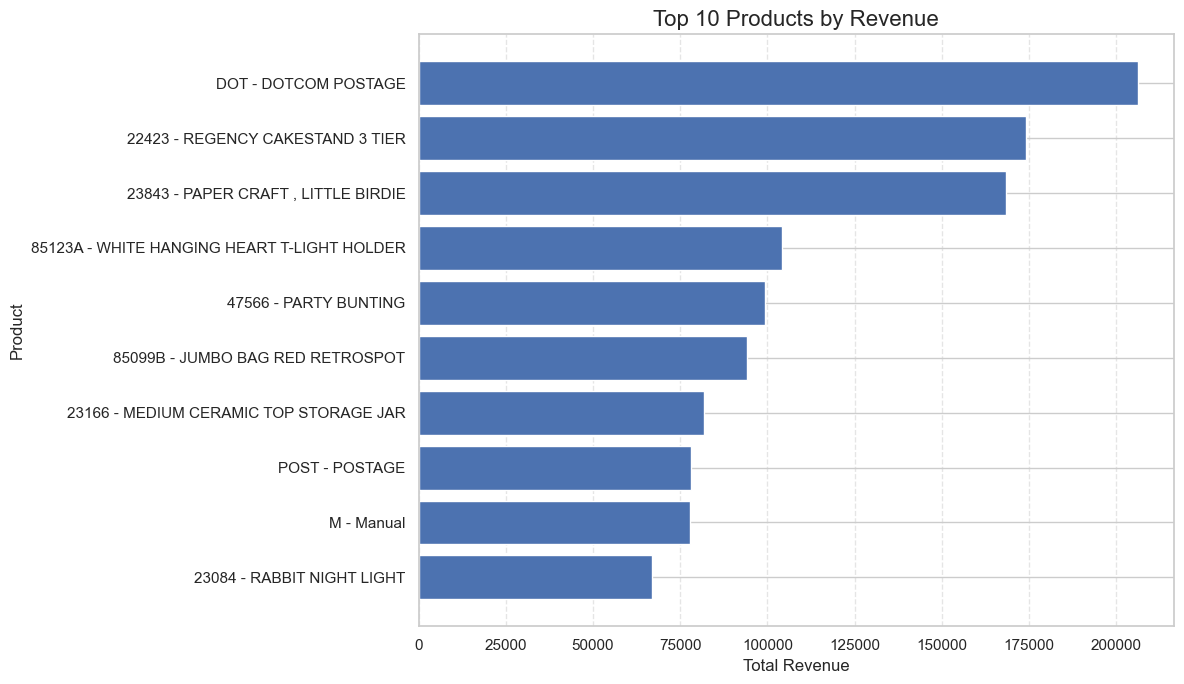

Top 10 Products by Revenue:


,StockCode,Description,Revenue
0,DOT,DOTCOM POSTAGE,206248.77
1,22423,REGENCY CAKESTAND 3 TIER,174156.54
2,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24
4,47566,PARTY BUNTING,99445.23
5,85099B,JUMBO BAG RED RETROSPOT,94159.81
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
7,POST,POSTAGE,78101.88
8,M,Manual,77750.27
9,23084,RABBIT NIGHT LIGHT,66870.03


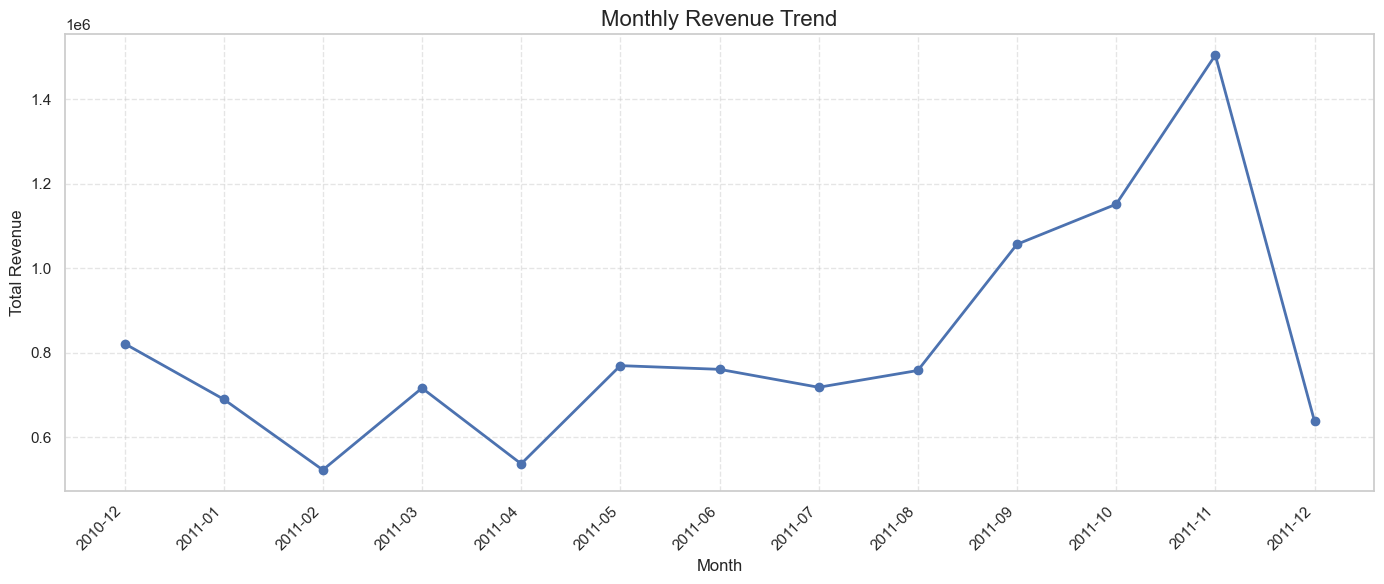

Monthly Revenue:


,Month,Revenue
0,2010-12,821452.730
1,2011-01,689811.610
2,2011-02,522545.560
3,2011-03,716215.260
4,2011-04,536968.491
5,2011-05,769296.610
6,2011-06,760547.010
7,2011-07,718076.121
8,2011-08,757841.380
9,2011-09,1056435.192



Main Trend Analysis
Highest revenue month: 2011-11 with 1,503,866.78
Lowest revenue month: 2011-02 with 522,545.56
Overall, revenue decreased from the first month to the last month.
Percentage change between the first and last months: -22.36%


In [48]:


# Q25. Product Revenue Comparison

top_products = (
    sales_viz.groupby(["StockCode", "Description"], dropna=False)["Revenue"]
    .sum()
    .reset_index()
    .sort_values("Revenue", ascending=False)
    .head(10)
)

top_products["Product"] = (
    top_products["StockCode"].astype(str)
    + " - "
    + top_products["Description"].fillna("Unknown Product").astype(str)
)

top_products = top_products.sort_values("Revenue", ascending=True)

plt.figure(figsize=(12, 7))
plt.barh(top_products["Product"], top_products["Revenue"])

plt.title("Top 10 Products by Revenue", fontsize=16)
plt.xlabel("Total Revenue", fontsize=12)
plt.ylabel("Product", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print("Top 10 Products by Revenue:")
display(top_products[["StockCode", "Description", "Revenue"]].sort_values(
    "Revenue", ascending=False
).reset_index(drop=True))


# Q26. Monthly Sales Trend

sales_viz["YearMonth"] = sales_viz["InvoiceDate"].dt.to_period("M")

monthly_revenue = (
    sales_viz.groupby("YearMonth")["Revenue"]
    .sum()
    .reset_index()
    .sort_values("YearMonth")
)

monthly_revenue["Month"] = monthly_revenue["YearMonth"].astype(str)

plt.figure(figsize=(14, 6))
plt.plot(
    monthly_revenue["Month"],
    monthly_revenue["Revenue"],
    marker="o",
    linewidth=2,
    markersize=6
)

plt.title("Monthly Revenue Trend", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Revenue", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print("Monthly Revenue:")
display(monthly_revenue[["Month", "Revenue"]])

# Main Trend Explanation

highest_month = monthly_revenue.loc[monthly_revenue["Revenue"].idxmax()]
lowest_month = monthly_revenue.loc[monthly_revenue["Revenue"].idxmin()]

first_revenue = monthly_revenue.iloc[0]["Revenue"]
last_revenue = monthly_revenue.iloc[-1]["Revenue"]

if first_revenue != 0:
    percentage_change = ((last_revenue - first_revenue) / first_revenue) * 100
else:
    percentage_change = np.nan

print("\nMain Trend Analysis")
print(f"Highest revenue month: {highest_month['Month']} "
      f"with {highest_month['Revenue']:,.2f}")

print(f"Lowest revenue month: {lowest_month['Month']} "
      f"with {lowest_month['Revenue']:,.2f}")

if last_revenue > first_revenue:
    print("Overall, revenue increased from the first month to the last month.")
elif last_revenue < first_revenue:
    print("Overall, revenue decreased from the first month to the last month.")
else:
    print("Revenue was the same in the first and last months.")

if pd.notna(percentage_change):
    print(f"Percentage change between the first and last months: "
          f"{percentage_change:.2f}%")


---

# Part 6 — Seaborn Visualizations (Questions 27–28)

### Q27. Revenue distribution and outliers
Use a Seaborn boxplot to visualize the distribution of invoice values or transaction revenue. Handle extreme values thoughtfully: show the full distribution first, then optionally create a second view with a justified range. Explain what the outliers may represent.

### Q28. Correlation and final interactive dashboard chart
Choose suitable numeric features and create a Seaborn correlation heatmap with annotations. Then create at least one Plotly interactive chart (for example, monthly revenue by country or top products by revenue) with a meaningful hover tooltip. Write two insights from the visualizations.




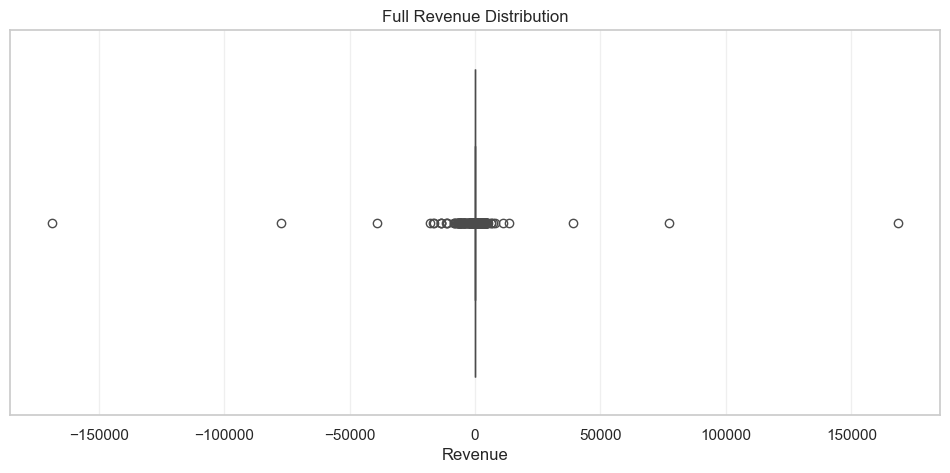

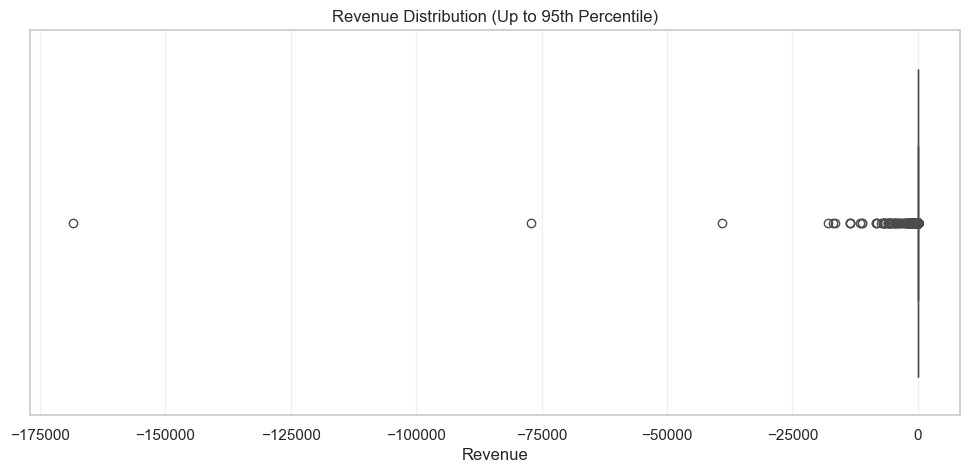

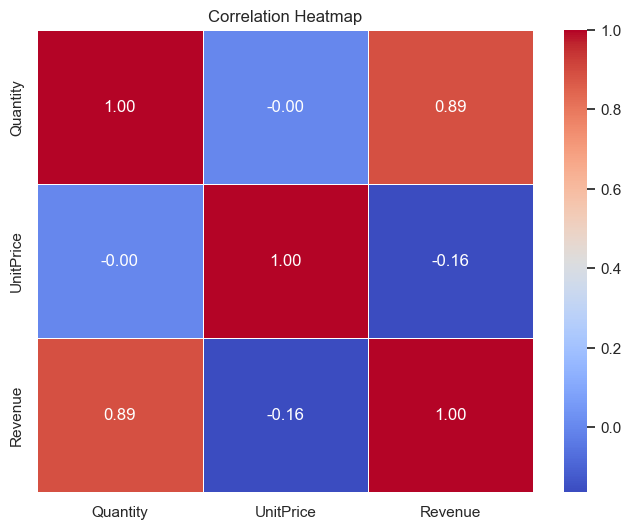

Key Insights:
1. The boxplot shows that most transactions have relatively low revenue, while some transactions have unusually high values. These outliers may represent bulk purchases or large orders.
2. The monthly revenue chart helps identify changes in sales performance over time. Revenue peaks indicate months with higher sales activity, while decreases may indicate lower demand or seasonal changes.


In [49]:
# Plotly chart workspace
df['Revenue'] = df['Quantity'] * df['UnitPrice']

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M').astype(str)

# Q27: Revenue Distribution and Outliers

plt.figure(figsize=(12, 5))
sns.boxplot(x=df['Revenue'])
plt.title('Full Revenue Distribution')
plt.xlabel('Revenue')
plt.grid(axis='x', alpha=0.3)
plt.show()

upper_limit = df['Revenue'].quantile(0.95)

plt.figure(figsize=(12, 5))
sns.boxplot(x=df[df['Revenue'] <= upper_limit]['Revenue'])
plt.title('Revenue Distribution (Up to 95th Percentile)')
plt.xlabel('Revenue')
plt.grid(axis='x', alpha=0.3)
plt.show()

# Q28: Correlation Heatmap

numeric_features = ['Quantity', 'UnitPrice', 'Revenue']

correlation_matrix = df[numeric_features].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)
plt.title('Correlation Heatmap')
plt.show()

# Q28: Interactive Monthly Revenue Chart

monthly_revenue = (
    df.groupby('YearMonth')['Revenue']
    .sum()
    .reset_index()
)

fig = px.line(
    monthly_revenue,
    x='YearMonth',
    y='Revenue',
    markers=True,
    title='Monthly Revenue Trend',
    labels={
        'YearMonth': 'Month',
        'Revenue': 'Total Revenue'
    },
    hover_data={'Revenue': ':.2f'}
)

fig.update_layout(
    template='plotly_white',
    hovermode='x unified'
)

fig.show()

# Key Insights

print("Key Insights:")

print("1. The boxplot shows that most transactions have relatively low revenue, while some transactions have unusually high values. These outliers may represent bulk purchases or large orders.")

print("2. The monthly revenue chart helps identify changes in sales performance over time. Revenue peaks indicate months with higher sales activity, while decreases may indicate lower demand or seasonal changes.")



## Final Project Conclusion

Write a concise conclusion containing:

1. The three most important data-quality issues you discovered.
2. The cleaning decisions you made and why.
3. The top product and top country by revenue.
4. One important trend in sales, customers, or returns.
5. Three actionable business recommendations.

## Publishing and Submission

- Restart the kernel and run all cells from top to bottom.
- Make sure your notebook contains no errors and all charts are visible.
- Publish the completed notebook publicly on Kaggle or GitHub.
- Publish a LinkedIn post describing your **3 most interesting findings** and include the notebook link.
- Submit both links: **Notebook URL** and **LinkedIn post URL**.


In [50]:

# Final Project Conclusion

# Top Product by Revenue
product_revenue = df.groupby('Description')['Revenue'].sum().sort_values(ascending=False)
top_product = product_revenue.index[0]
top_product_revenue = product_revenue.iloc[0]

# Top Country by Revenue
country_revenue = df.groupby('Country')['Revenue'].sum().sort_values(ascending=False)
top_country = country_revenue.index[0]
top_country_revenue = country_revenue.iloc[0]

# Monthly Sales Trend
monthly_sales = df.groupby('YearMonth')['Revenue'].sum()
best_month = monthly_sales.idxmax()
best_month_revenue = monthly_sales.max()

# Data Quality
missing_values = df.isnull().sum().sum()
duplicates = df.duplicated().sum()
negative_transactions = (df['Revenue'] < 0).sum()

# Display Conclusion
print("=" * 60)
print("FINAL PROJECT CONCLUSION")
print("=" * 60)

print("\n1. Top Product by Revenue")
print(f"Product: {top_product}")
print(f"Revenue: {top_product_revenue:.2f}")

print("\n2. Top Country by Revenue")
print(f"Country: {top_country}")
print(f"Revenue: {top_country_revenue:.2f}")

print("\n3. Important Sales Trend")
print(f"Best Sales Month: {best_month}")
print(f"Monthly Revenue: {best_month_revenue:.2f}")

print("\n4. Three Data Quality Issues")
print(f"- Missing values: {missing_values}")
print(f"- Duplicate records: {duplicates}")
print(f"- Negative revenue transactions: {negative_transactions}")

print("\n5. Cleaning Decisions")
print("- Missing values were handled using suitable methods.")
print("- Duplicate records were removed to avoid inaccurate results.")
print("- Negative transactions were checked and preserved when they represented valid returns.")

print("\n6. Business Recommendations")
print("- Focus on promoting the top revenue-generating products.")
print("- Improve marketing strategies in the highest-performing country.")
print("- Analyze customer returns and monthly sales trends to improve business performance.")

print("\n" + "=" * 60)


FINAL PROJECT CONCLUSION

1. Top Product by Revenue
Product: DOTCOM POSTAGE
Revenue: 206245.48

2. Top Country by Revenue
Country: United Kingdom
Revenue: 8187806.36

3. Important Sales Trend
Best Sales Month: 2011-11
Monthly Revenue: 1461756.25

4. Three Data Quality Issues
- Missing values: 136534
- Duplicate records: 5268
- Negative revenue transactions: 9290

5. Cleaning Decisions
- Missing values were handled using suitable methods.
- Duplicate records were removed to avoid inaccurate results.
- Negative transactions were checked and preserved when they represented valid returns.

6. Business Recommendations
- Focus on promoting the top revenue-generating products.
- Improve marketing strategies in the highest-performing country.
- Analyze customer returns and monthly sales trends to improve business performance.

